# Morphological and Binary Operations

Mathematical morphology is a set of operations that probe an image with a small shape, the *structuring element* (or *footprint*), to modify the shape of objects. pyclesperanto implements the classical operations for both binary and grayscale images, in 2D and 3D:

- **Binary logical operations**: `binary_not`, `binary_and`, `binary_or`, `binary_xor`, `binary_subtract`
- **Binary morphology**: `binary_erode`, `binary_dilate`, `binary_opening`, `binary_closing`, `binary_edge_detection`, `binary_supinf`, `binary_infsup`
- **Grayscale morphology**: `grayscale_erode`, `grayscale_dilate`, `grayscale_opening`, `grayscale_closing`, `top_hat`, `bottom_hat`
- **Custom footprints**: `erosion`, `opening`, `closing`
- **Skeletonization**: `skeletonize`

> See also [Wikipedia: Mathematical morphology](https://en.wikipedia.org/wiki/Mathematical_morphology)

In [1]:
import pyclesperanto as cle
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, morphology

cle.select_device()

(OpenCL) Apple M5 Max (OpenCL 1.2)
	Vendor:                      Apple
	Driver Version:              1.2 1.0
	Device Type:                 GPU
	Compute Units:               40
	Global Memory Size:          53084 MB
	Local Memory Size:           32 KB
	Maximum Buffer Size:         9953 MB
	Max Clock Frequency:         1000 MHz
	Image Support:               Yes

We use a small helper to display several images side by side.

In [2]:
def show(images, titles, cmap="gray", size=4):
    fig, axs = plt.subplots(1, len(images), figsize=(size * len(images), size))
    for ax, image, title in zip(np.atleast_1d(axs), images, titles):
        ax.imshow(cle.pull(image), cmap=cmap, interpolation="nearest")
        ax.set_title(title)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

## Sample data

We use a few images from the scikit-image [data module](https://scikit-image.org/docs/stable/api/skimage.data.html):
- `horse`: a binary silhouette
- `coins`: a grayscale image
- `binary_blobs`: synthetic random binary blobs, in 2D and 3D

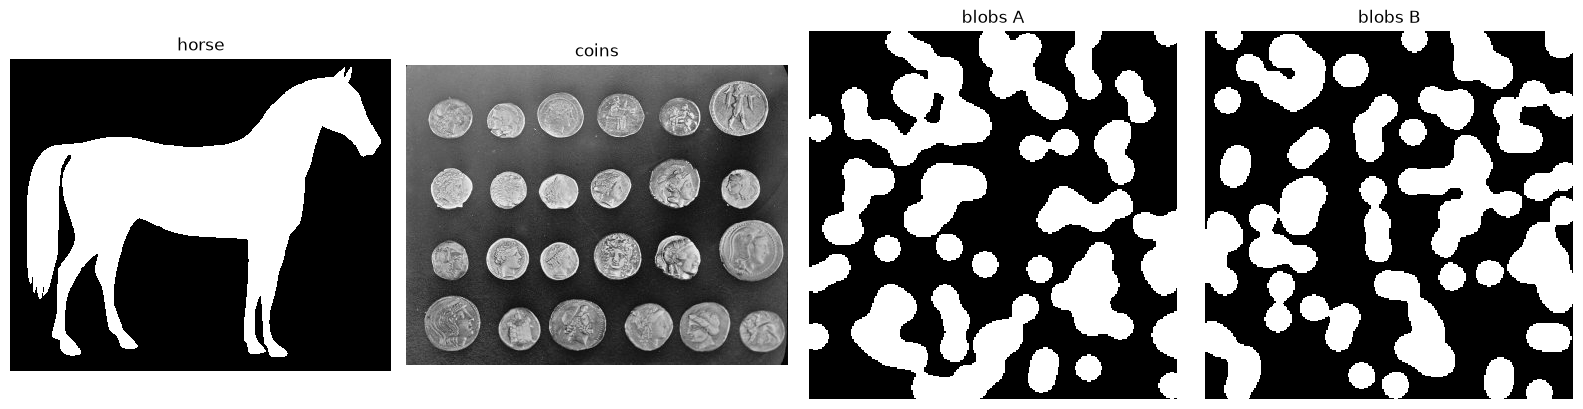

In [3]:
horse = cle.push((data.horse() == 0).astype(np.uint8))
coins = cle.push(data.coins().astype(np.float32))
blobs_a = cle.push(data.binary_blobs(length=256, volume_fraction=0.4, rng=1).astype(np.uint8))
blobs_b = cle.push(data.binary_blobs(length=256, volume_fraction=0.4, rng=2).astype(np.uint8))

show([horse, coins, blobs_a, blobs_b], ["horse", "coins", "blobs A", "blobs B"])

## Binary logical operations

Binary images can be combined pixel-wise with logical operators. All non-zero pixels are considered as `True`.

| Function | Operation |
|---|---|
| `binary_not` | NOT A |
| `binary_and` | A AND B |
| `binary_or` | A OR B |
| `binary_xor` | A XOR B |
| `binary_subtract` | A AND (NOT B) |

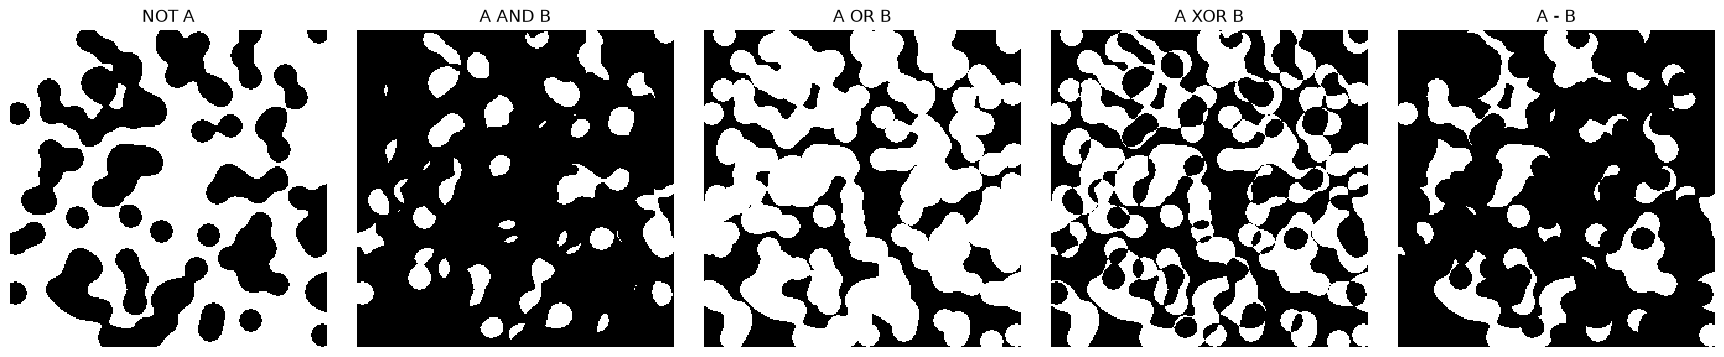

In [4]:
not_a = cle.binary_not(blobs_a)
a_and_b = cle.binary_and(blobs_a, blobs_b)
a_or_b = cle.binary_or(blobs_a, blobs_b)
a_xor_b = cle.binary_xor(blobs_a, blobs_b)
a_minus_b = cle.binary_subtract(blobs_a, blobs_b)

show(
    [not_a, a_and_b, a_or_b, a_xor_b, a_minus_b],
    ["NOT A", "A AND B", "A OR B", "A XOR B", "A - B"],
    size=3.5,
)

## Binary erosion and dilation

**Erosion** shrinks objects: a pixel stays foreground only if all pixels in its neighborhood are foreground. **Dilation** grows objects: a pixel becomes foreground if any pixel in its neighborhood is foreground.

The neighborhood is defined by a radius per dimension and a `connectivity`:
- `"box"`: a rectangle (Moore neighborhood, 8 neighbors in 2D / 26 in 3D for radius 1)
- `"sphere"`: an ellipse (von Neumann neighborhood, 4 neighbors in 2D / 6 in 3D for radius 1)

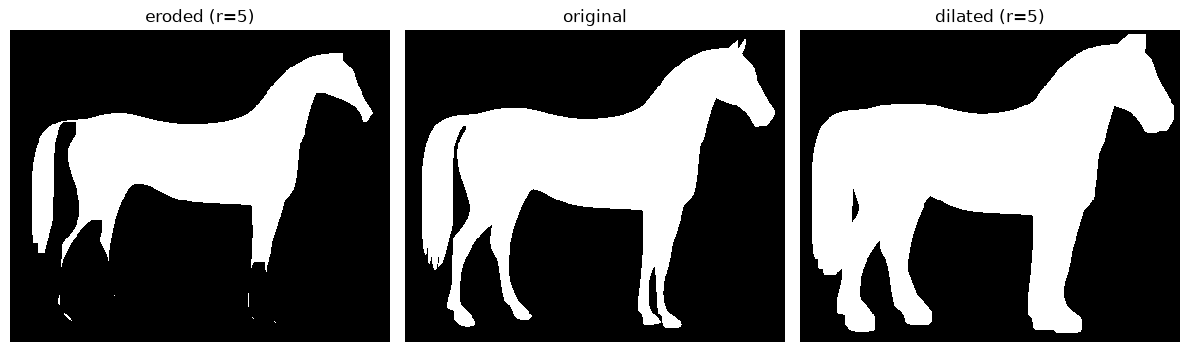

In [5]:
eroded = cle.binary_erode(horse, radius_x=5, radius_y=5, connectivity="box")
dilated = cle.binary_dilate(horse, radius_x=5, radius_y=5, connectivity="box")

show([eroded, horse, dilated], ["eroded (r=5)", "original", "dilated (r=5)"])

The connectivity changes the shape of the footprint. Dilating a single pixel reveals it directly:

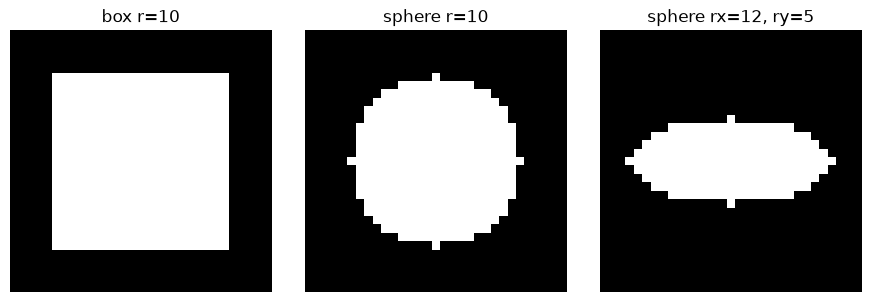

In [6]:
point_np = np.zeros((31, 31), dtype=np.uint8)
point_np[15, 15] = 1
point = cle.push(point_np)

show(
    [
        cle.binary_dilate(point, radius_x=10, radius_y=10, connectivity="box"),
        cle.binary_dilate(point, radius_x=10, radius_y=10, connectivity="sphere"),
        cle.binary_dilate(point, radius_x=12, radius_y=5, connectivity="sphere"),
    ],
    ["box r=10", "sphere r=10", "sphere rx=12, ry=5"],
    size=3,
)

## Binary opening and closing

- **Opening** = erosion followed by dilation. It removes small objects and thin protrusions, and separates objects connected by thin bridges.
- **Closing** = dilation followed by erosion. It fills small holes and gaps, and connects close objects.

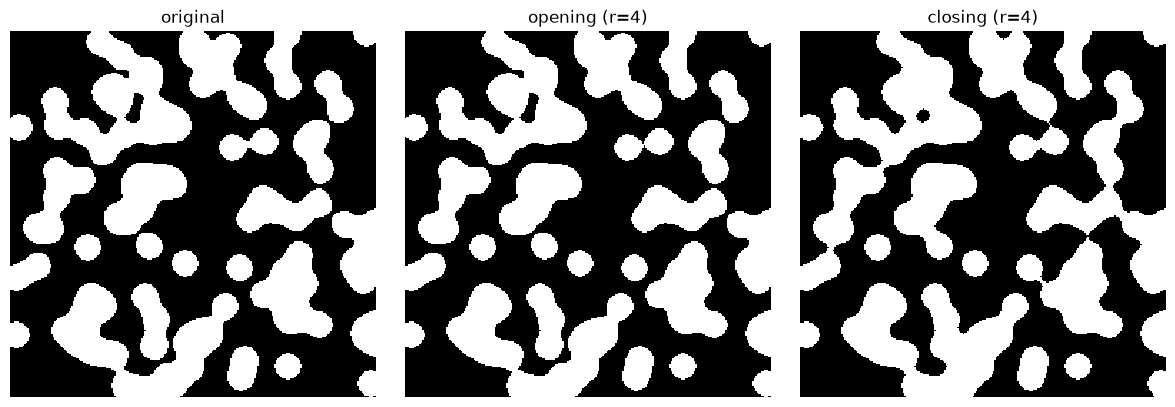

In [7]:
opened = cle.binary_opening(blobs_a, radius_x=4, radius_y=4, connectivity="sphere")
closed = cle.binary_closing(blobs_a, radius_x=4, radius_y=4, connectivity="sphere")

show([blobs_a, opened, closed], ["original", "opening (r=4)", "closing (r=4)"])

Differences between the original and the result show what each operation removed or added:

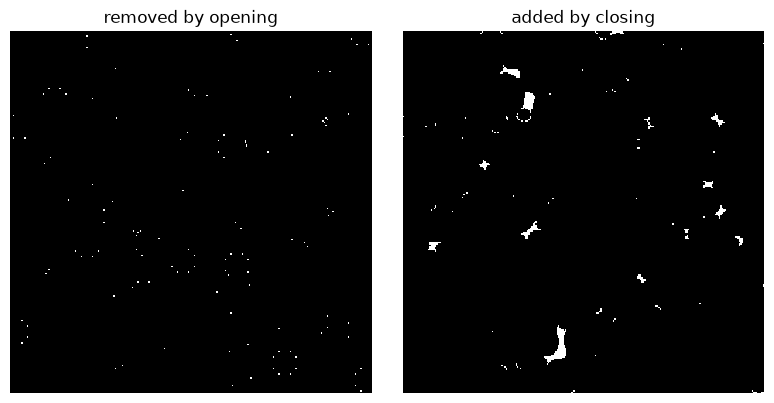

In [8]:
show(
    [cle.binary_subtract(blobs_a, opened), cle.binary_subtract(closed, blobs_a)],
    ["removed by opening", "added by closing"],
)

## Object borders

`binary_edge_detection` returns the foreground pixels touching the background. Combining erosion/dilation with `binary_subtract` gives inner and outer borders of any thickness.

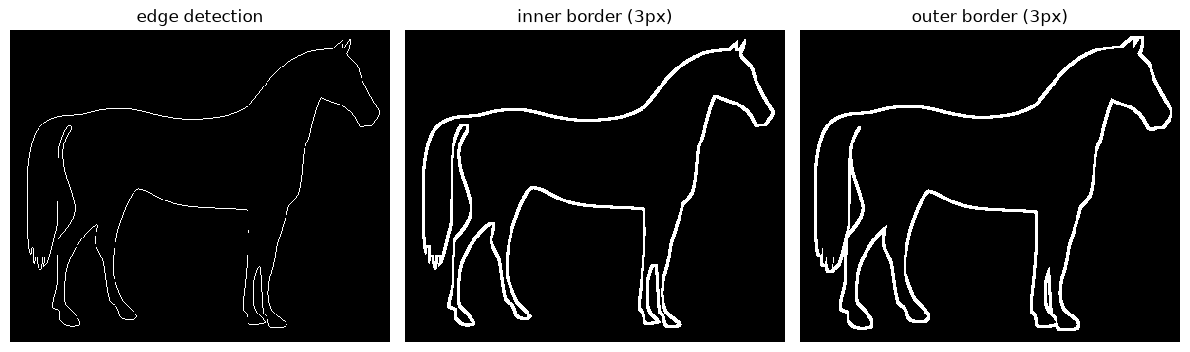

In [9]:
edges = cle.binary_edge_detection(horse)
inner_border = cle.binary_subtract(horse, cle.binary_erode(horse, radius_x=3, radius_y=3))
outer_border = cle.binary_subtract(cle.binary_dilate(horse, radius_x=3, radius_y=3), horse)

show([edges, inner_border, outer_border], ["edge detection", "inner border (3px)", "outer border (3px)"])

## Binary smoothing with sup-inf and inf-sup

`binary_supinf` and `binary_infsup` are morphological smoothing operators based on the supremum / infimum of erosions / dilations along line segments in several directions. They are used, for instance, as the curvature-like smoothing step of morphological active contours (`morphological_chan_vese`). They remove small spurs (`supinf`) or fill small dents (`infsup`) while preserving the overall shape.

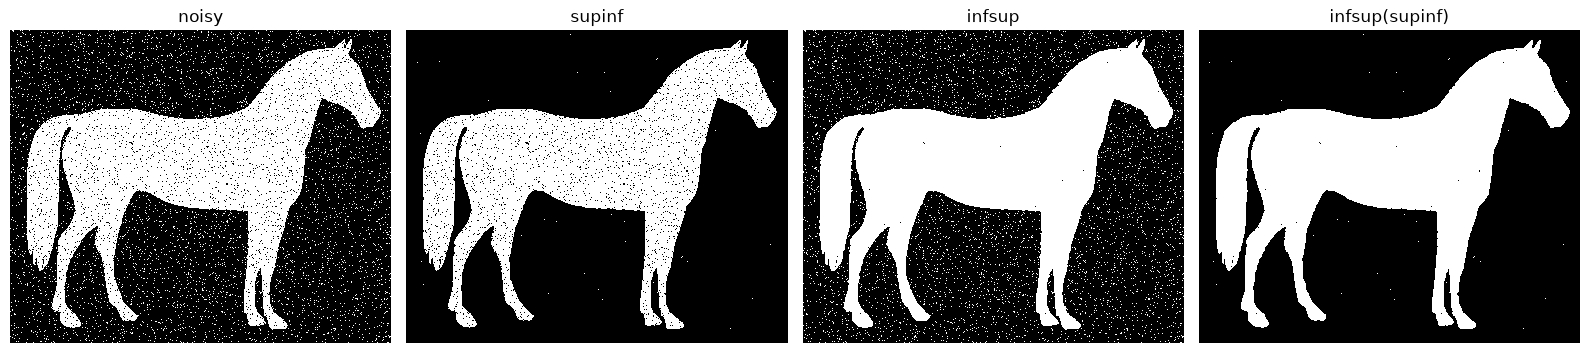

In [10]:
noisy_np = cle.pull(horse).copy()
rng = np.random.default_rng(0)
noisy_np[rng.random(noisy_np.shape) < 0.05] ^= 1
noisy = cle.push(noisy_np)

supinf = cle.binary_supinf(noisy)
infsup = cle.binary_infsup(noisy)
both = cle.binary_infsup(cle.binary_supinf(noisy))

show([noisy, supinf, infsup, both], ["noisy", "supinf", "infsup", "infsup(supinf)"])

## Custom footprints

`erosion`, `opening` and `closing` accept any binary footprint image with the same dimensionality as the input. Here we use footprints generated with `skimage.morphology`, plus a hand-made diagonal line. Note how the shape of the footprint is imprinted on the result.

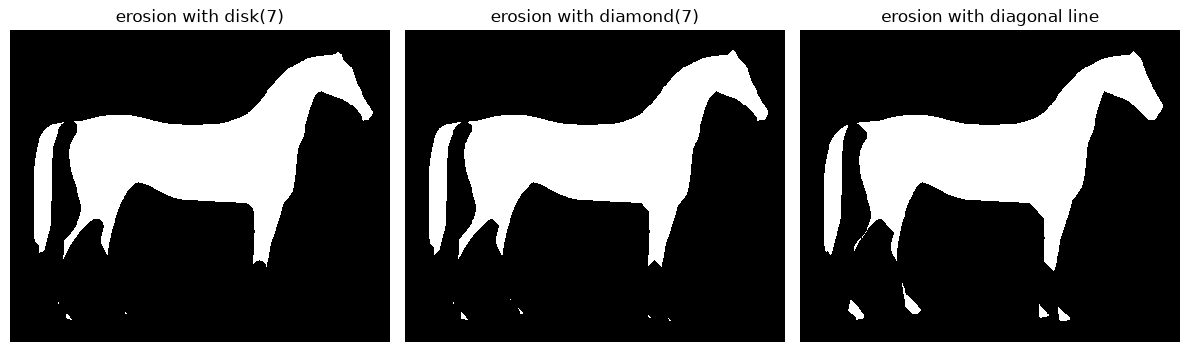

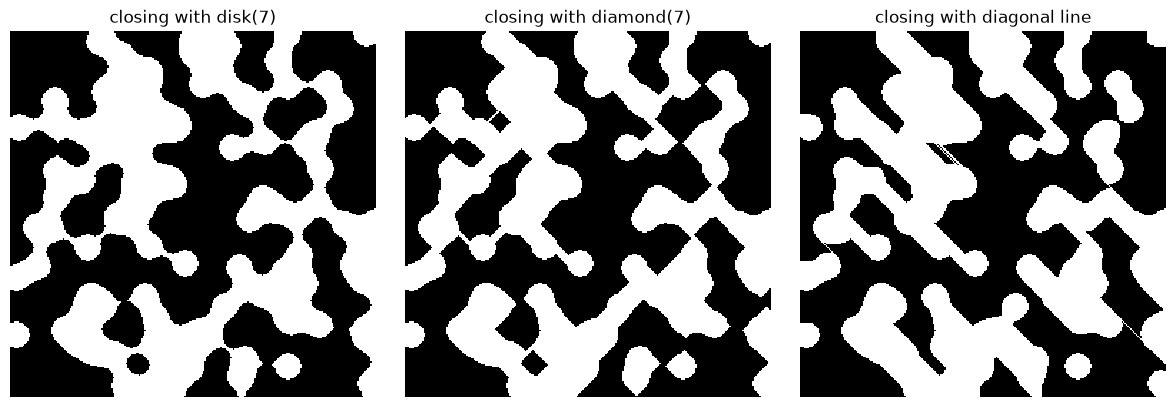

In [11]:
footprints = {
    "disk(7)": morphology.disk(7),
    "diamond(7)": morphology.diamond(7),
    "diagonal line": np.eye(15, dtype=np.uint8),
}

eroded_images, closed_images, titles = [], [], []
for name, fp in footprints.items():
    fp = cle.push(fp.astype(np.uint8))
    eroded_images.append(cle.erosion(horse, fp))
    closed_images.append(cle.closing(blobs_a, fp))
    titles.append(name)

show(eroded_images, [f"erosion with {t}" for t in titles])
show(closed_images, [f"closing with {t}" for t in titles])

## Grayscale morphology

On grayscale images, erosion and dilation become local **minimum** and **maximum** filters. Opening removes bright structures smaller than the footprint, and closing removes dark structures smaller than the footprint.

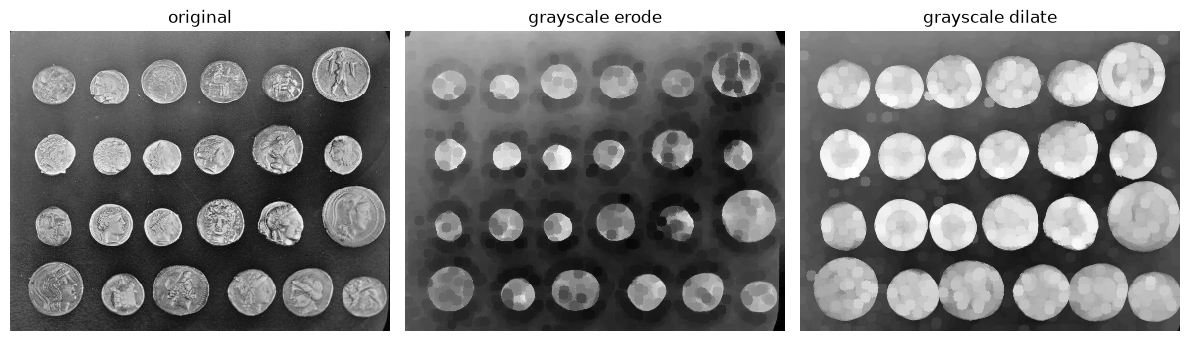

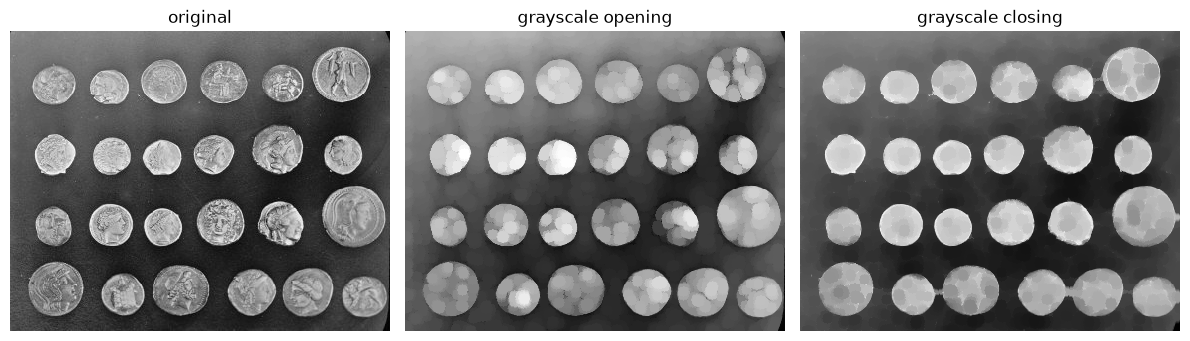

In [12]:
r = 5
g_eroded = cle.grayscale_erode(coins, radius_x=r, radius_y=r, connectivity="sphere")
g_dilated = cle.grayscale_dilate(coins, radius_x=r, radius_y=r, connectivity="sphere")
g_opened = cle.grayscale_opening(coins, radius_x=r, radius_y=r, connectivity="sphere")
g_closed = cle.grayscale_closing(coins, radius_x=r, radius_y=r, connectivity="sphere")

show([coins, g_eroded, g_dilated], ["original", "grayscale erode", "grayscale dilate"])
show([coins, g_opened, g_closed], ["original", "grayscale opening", "grayscale closing"])

### Morphological gradient

The difference between dilation and erosion highlights object outlines.

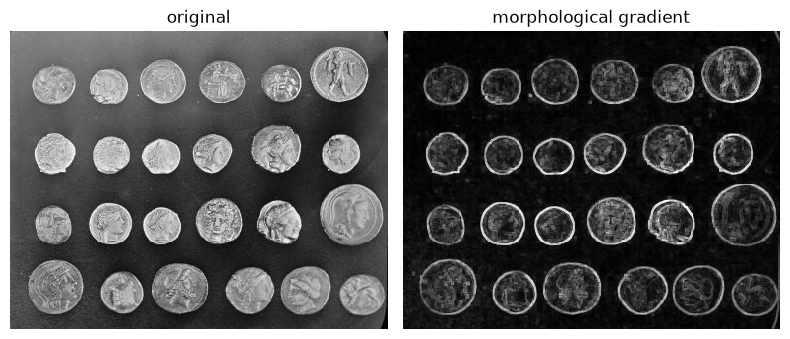

In [13]:
gradient = cle.subtract_images(
    cle.grayscale_dilate(coins, radius_x=1, radius_y=1),
    cle.grayscale_erode(coins, radius_x=1, radius_y=1),
)
show([coins, gradient], ["original", "morphological gradient"])

### Top-hat and bottom-hat

- **Top-hat** = image - opening: extracts bright structures smaller than the footprint. It is commonly used for background subtraction.
- **Bottom-hat** = closing - image: extracts dark structures smaller than the footprint.

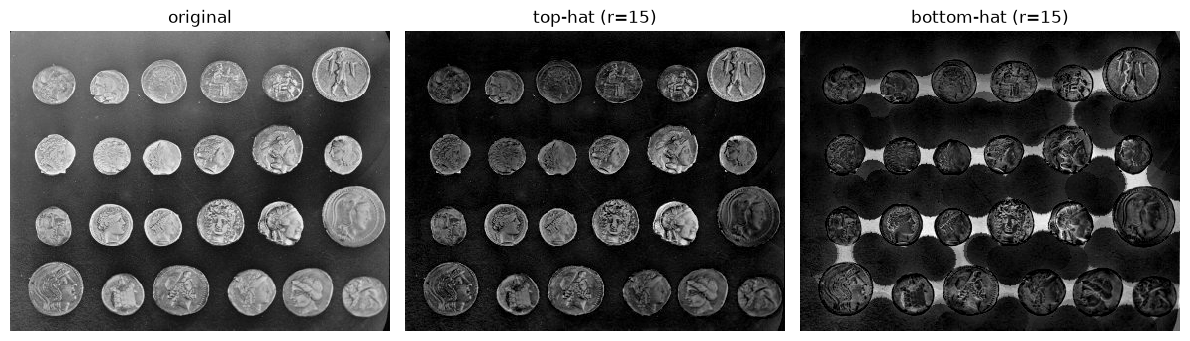

In [14]:
top = cle.top_hat(coins, radius_x=15, radius_y=15, connectivity="sphere")
bottom = cle.bottom_hat(coins, radius_x=15, radius_y=15, connectivity="sphere")

show([coins, top, bottom], ["original", "top-hat (r=15)", "bottom-hat (r=15)"])

## Skeletonization

`skeletonize` reduces binary objects to one-pixel-wide lines while preserving their topology: the number of objects, holes (and cavities in 3D) and end points are kept. It works on 2D and 3D images, and the result is similar to scikit-image's `skeletonize` (Lee method in 3D) — not necessarily identical pixel by pixel.

### 2D skeleton

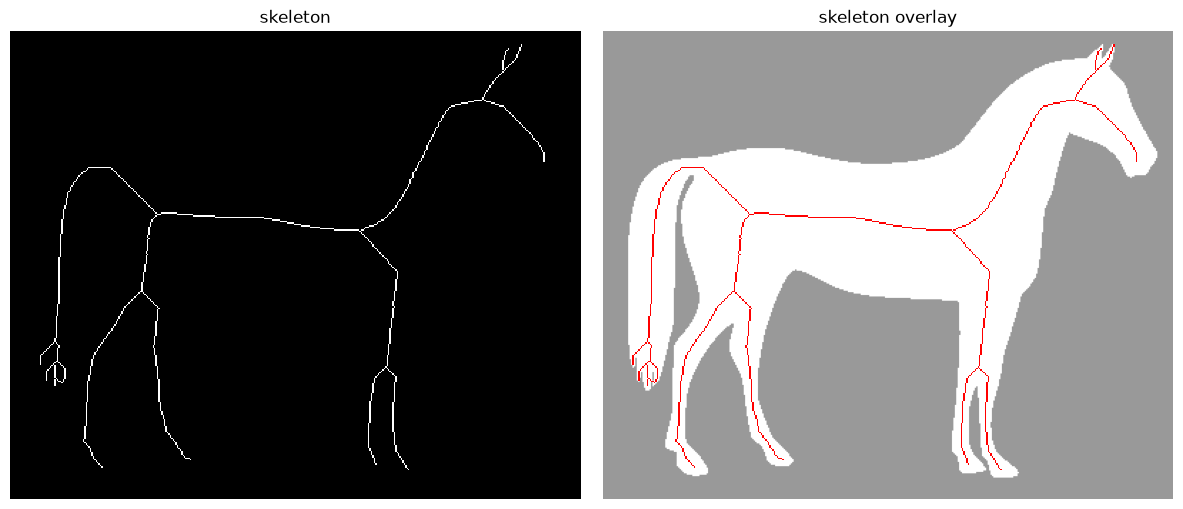

In [15]:
skeleton = cle.skeletonize(horse)

fig, axs = plt.subplots(1, 2, figsize=(12, 5))
axs[0].imshow(cle.pull(skeleton), cmap="gray", interpolation="nearest")
axs[0].set_title("skeleton")
axs[1].imshow(cle.pull(horse), cmap="gray", alpha=0.4)
axs[1].imshow(np.ma.masked_equal(cle.pull(skeleton), 0), cmap="autumn", interpolation="nearest")
axs[1].set_title("skeleton overlay")
for ax in axs:
    ax.axis("off")
plt.tight_layout()
plt.show()

### Comparison with scikit-image

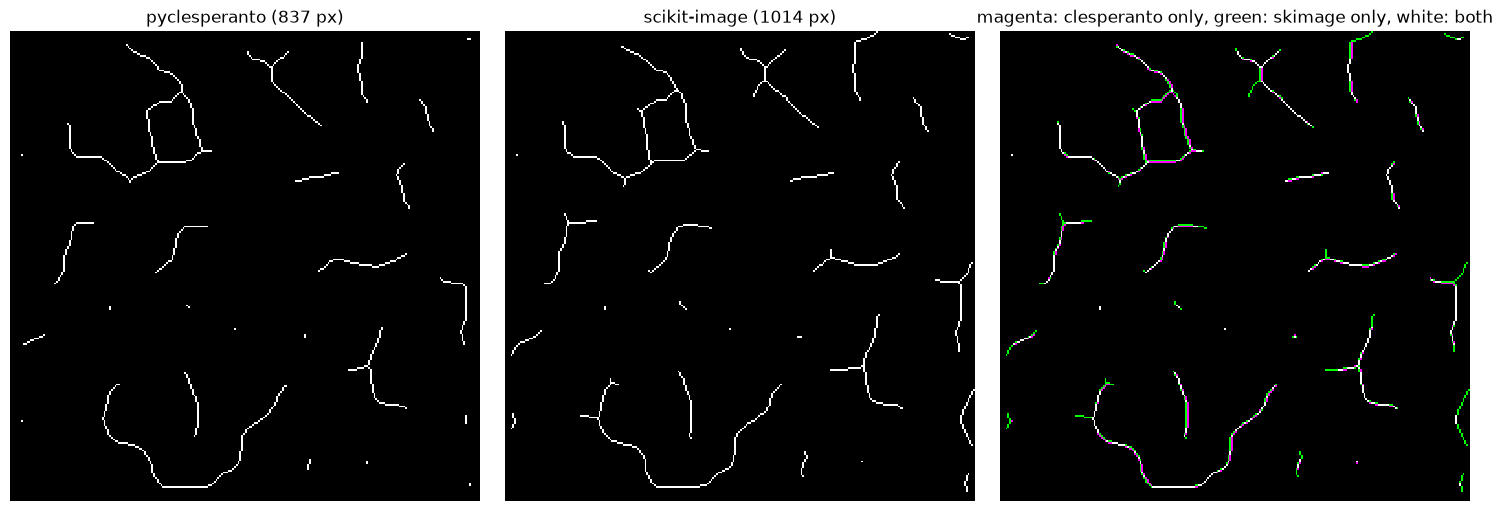

In [16]:
blobs_skeleton = cle.pull(cle.skeletonize(blobs_a)).astype(bool)
blobs_skeleton_sk = morphology.skeletonize(cle.pull(blobs_a).astype(bool))

overlay = np.zeros(blobs_skeleton.shape + (3,))
overlay[blobs_skeleton] += [1, 0, 1]
overlay[blobs_skeleton_sk] += [0, 1, 0]
overlay = overlay.clip(0, 1)

fig, axs = plt.subplots(1, 3, figsize=(15, 5))
axs[0].imshow(blobs_skeleton, cmap="gray", interpolation="nearest")
axs[0].set_title(f"pyclesperanto ({blobs_skeleton.sum()} px)")
axs[1].imshow(blobs_skeleton_sk, cmap="gray", interpolation="nearest")
axs[1].set_title(f"scikit-image ({blobs_skeleton_sk.sum()} px)")
axs[2].imshow(overlay, interpolation="nearest")
axs[2].set_title("magenta: clesperanto only, green: skimage only, white: both")
for ax in axs:
    ax.axis("off")
plt.tight_layout()
plt.show()

### 3D skeleton

The same function works on 3D volumes. We display a maximum intensity projection of the binary volume, and a projection of its skeleton coloured by depth (z position).

foreground voxels: 104858
skeleton voxels:   815


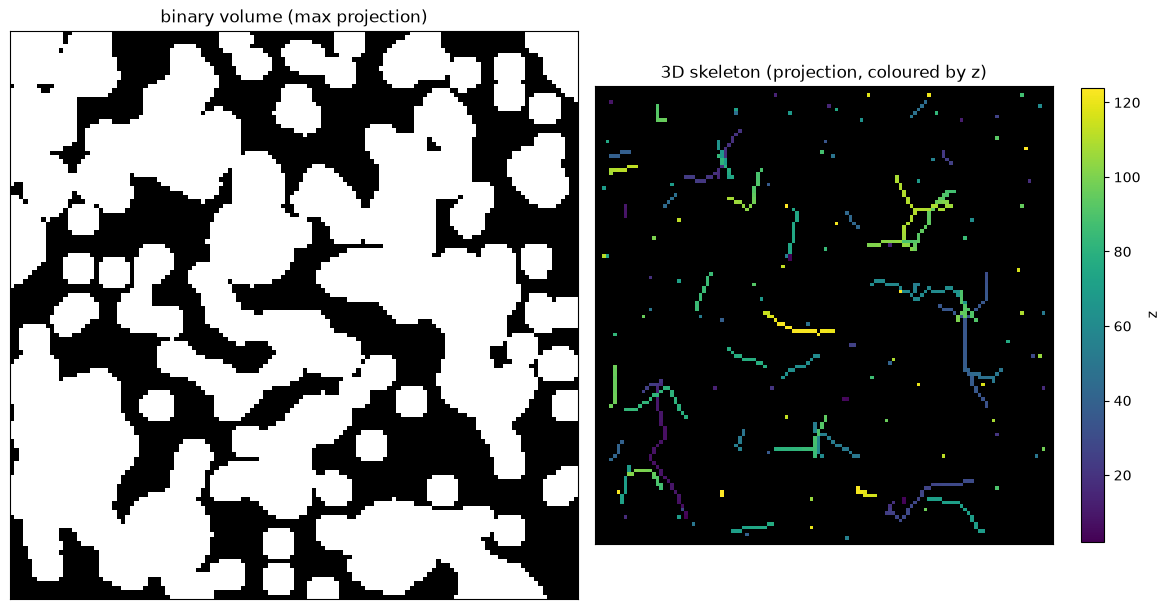

In [17]:
blobs_3d = cle.push(
    data.binary_blobs(length=128, n_dim=3, volume_fraction=0.05, blob_size_fraction=0.15, rng=3).astype(np.uint8)
)
skeleton_3d = cle.pull(cle.skeletonize(blobs_3d)).astype(bool)

print("foreground voxels:", int(cle.pull(blobs_3d).sum()))
print("skeleton voxels:  ", int(skeleton_3d.sum()))

z = np.arange(skeleton_3d.shape[0])[:, None, None]
depth = np.where(skeleton_3d.any(axis=0), (skeleton_3d * z).max(axis=0), np.nan)

fig, axs = plt.subplots(1, 2, figsize=(12, 6))
axs[0].imshow(cle.pull(cle.maximum_z_projection(blobs_3d)), cmap="gray", interpolation="nearest")
axs[0].set_title("binary volume (max projection)")
axs[1].set_facecolor("black")
im = axs[1].imshow(depth, cmap="viridis", interpolation="nearest")
axs[1].set_title("3D skeleton (projection, coloured by z)")
fig.colorbar(im, ax=axs[1], label="z", shrink=0.8)
for ax in axs:
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()

The skeleton is easier to understand in 3D. With [napari](https://napari.org) we render the binary volume as a translucent surface and the skeleton inside it. The viewer opens in a separate window, where you can rotate and zoom; `nbscreenshot` captures it in the notebook.

In [ ]:
import napari
from napari.utils import nbscreenshot

viewer = napari.Viewer(ndisplay=3)
viewer.add_image(
    cle.pull(blobs_3d).astype(np.float32),
    name="binary volume",
    rendering="iso",
    iso_threshold=0.5,
    contrast_limits=(0, 1),
    colormap="gray",
    opacity=0.25,
    blending="translucent_no_depth",
)
viewer.add_image(
    skeleton_3d.astype(np.uint8),
    name="skeleton",
    rendering="mip",
    contrast_limits=(0, 1),
    colormap="magenta",
    blending="additive",
)
viewer.camera.angles = (-20, 35, 130)
viewer.camera.zoom *= 1.2

# napari.run()
nbscreenshot(viewer, canvas_only=True)

### Application: measuring skeleton length

Combined with connected component labeling, the skeleton gives an estimate of the length of each object, here the number of skeleton pixels per object.

number of objects: 25
longest skeleton (px): 207


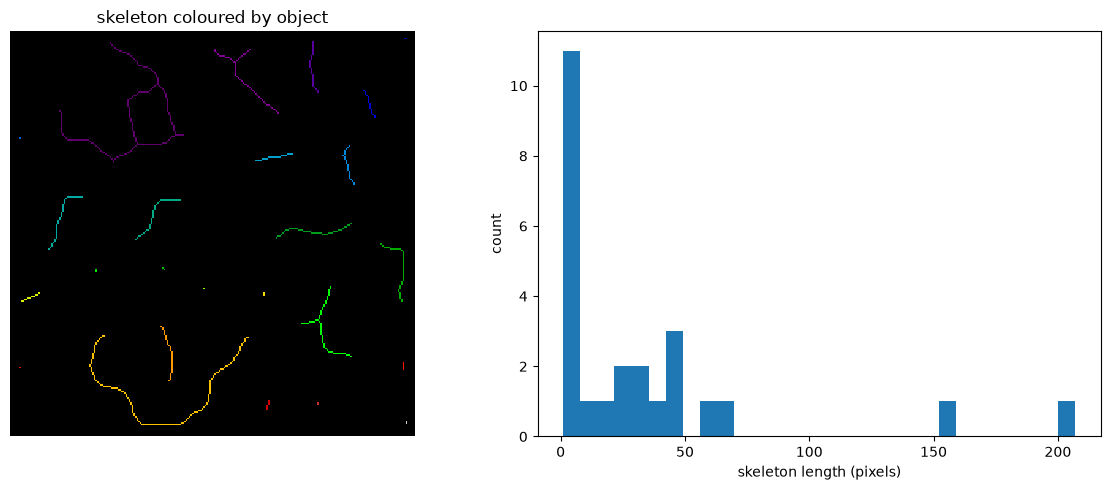

In [19]:
labels = cle.connected_component_labeling(blobs_a, connectivity="box")
labelled_skeleton = cle.multiply_images(labels, cle.skeletonize(blobs_a))

lengths = np.bincount(cle.pull(labelled_skeleton).astype(np.int64).ravel())[1:]
print("number of objects:", int(cle.maximum_of_all_pixels(labels)))
print("longest skeleton (px):", lengths.max())

fig, axs = plt.subplots(1, 2, figsize=(12, 5))
axs[0].imshow(cle.pull(labelled_skeleton), cmap="nipy_spectral", interpolation="nearest")
axs[0].set_title("skeleton coloured by object")
axs[0].axis("off")
axs[1].hist(lengths[lengths > 0], bins=30)
axs[1].set_xlabel("skeleton length (pixels)")
axs[1].set_ylabel("count")
plt.tight_layout()
plt.show()